### Required Assignment 5.1: Will the Customer Accept the Coupon?

Context

Imagine driving through town and a coupon is delivered to your cell phone for a restaurant near where you are driving. Would you accept that coupon and take a short detour to the restaurant? Would you accept the coupon but use it on a subsequent trip? Would you ignore the coupon entirely? What if the coupon was for a bar instead of a restaurant? What about a coffee house? Would you accept a bar coupon with a minor passenger in the car? What about if it was just you and your partner in the car? Would weather impact the rate of acceptance? What about the time of day?

Obviously, proximity to the business is a factor on whether the coupon is delivered to the driver or not, but what are the factors that determine whether a driver accepts the coupon once it is delivered to them? How would you determine whether a driver is likely to accept a coupon?

Overview

The goal of this project is to use what you know about visualizations and probability distributions to distinguish between customers who accepted a driving coupon versus those that did not.

Data

This data comes to us from the UCI Machine Learning repository and was collected via a survey on Amazon Mechanical Turk. The survey describes different driving scenarios including the destination, current time, weather, passenger, etc., and then ask the person whether he will accept the coupon if he is the driver. Answers that the user will drive there ‘right away’ or ‘later before the coupon expires’ are labeled as ‘Y = 1’ and answers ‘no, I do not want the coupon’ are labeled as ‘Y = 0’.  There are five different types of coupons -- less expensive restaurants (under \$20), coffee houses, carry out & take away, bar, and more expensive restaurants (\$20 - $50).

Deliverables

Your final product should be a brief report that highlights the differences between customers who did and did not accept the coupons.  To explore the data you will utilize your knowledge of plotting, statistical summaries, and visualization using Python. You will publish your findings in a public facing github repository as your first portfolio piece.





### Data Description
Keep in mind that these values mentioned below are average values.

The attributes of this data set include:
1. User attributes
    -  Gender: male, female
    -  Age: below 21, 21 to 25, 26 to 30, etc.
    -  Marital Status: single, married partner, unmarried partner, or widowed
    -  Number of children: 0, 1, or more than 1
    -  Education: high school, bachelors degree, associates degree, or graduate degree
    -  Occupation: architecture & engineering, business & financial, etc.
    -  Annual income: less than \\$12500, \\$12500 - \\$24999, \\$25000 - \\$37499, etc.
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she buys takeaway food: 0, less than 1, 1 to 3, 4 to 8 or greater
    than 8
    -  Number of times that he/she goes to a coffee house: 0, less than 1, 1 to 3, 4 to 8 or
    greater than 8
    -  Number of times that he/she eats at a restaurant with average expense less than \\$20 per
    person: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    

2. Contextual attributes
    - Driving destination: home, work, or no urgent destination
    - Location of user, coupon and destination: we provide a map to show the geographical
    location of the user, destination, and the venue, and we mark the distance between each
    two places with time of driving. The user can see whether the venue is in the same
    direction as the destination.
    - Weather: sunny, rainy, or snowy
    - Temperature: 30F, 55F, or 80F
    - Time: 10AM, 2PM, or 6PM
    - Passenger: alone, partner, kid(s), or friend(s)


3. Coupon attributes
    - time before it expires: 2 hours or one day

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from matplotlib.ticker import PercentFormatter

# Consistent, readable plot styling for the whole notebook
sns.set_theme(style='whitegrid', context='notebook')

### Problems

Use the prompts below to get started with your data analysis.

1. Read in the `coupons.csv` file.

In [2]:
data = pd.read_csv('data/coupons.csv')

In [3]:
data.head()

,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
0,No Urgent Place,Alone,Sunny,55,2PM,Restaurant(<20),1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,1
1,No Urgent Place,Friend(s),Sunny,80,10AM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,0
2,No Urgent Place,Friend(s),Sunny,80,10AM,Carry out & Take away,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,1
3,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0
4,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0


2. Investigate the dataset for missing or problematic data.

In [4]:
print(f'Rows: {data.shape[0]:,}  Columns: {data.shape[1]}')
print(f'Duplicate rows: {data.duplicated().sum()}')

# Count and percent of missing values for columns that have any
missing = data.isna().sum()
missing_report = pd.DataFrame({'missing': missing, 'percent': missing / len(data) * 100})
missing_report[missing_report['missing'] > 0].round(2)

Rows: 12,684  Columns: 26
Duplicate rows: 74


,missing,percent
car,12576,99.15
Bar,107,0.84
CoffeeHouse,217,1.71
CarryAway,151,1.19
RestaurantLessThan20,130,1.02
Restaurant20To50,189,1.49


In [5]:
# Columns with a single value, or that mirror another column, add no information
print('toCoupon_GEQ5min unique values:', data['toCoupon_GEQ5min'].unique())
print('direction_same == 1 - direction_opp for every row:',
      (data['direction_same'] == 1 - data['direction_opp']).all())

# Inspect the text codes used in the visit-frequency columns
data['Bar'].value_counts(dropna=False)

toCoupon_GEQ5min unique values: [1]
direction_same == 1 - direction_opp for every row: True


Bar
never    5197
less1    3482
1~3      2473
4~8      1076
gt8       349
NaN       107
Name: count, dtype: int64

Observations

- `car` is missing for 99% of rows, so it cannot be used.
- The five visit-frequency columns (`Bar`, `CoffeeHouse`, `CarryAway`, `RestaurantLessThan20`, `Restaurant20To50`) each have about 1-2% missing values.
- There are 74 exact duplicate rows.
- `toCoupon_GEQ5min` is always 1 and `direction_opp` is the exact opposite of `direction_same`, so both are redundant.
- The column `passanger` is misspelled, and the `age` and frequency columns are stored as text codes (e.g. `below21`, `50plus`, `less1`, `gt8`). These are handled with explicit category lists when filtering.

3. Decide what to do about your missing data -- drop, replace, other...

In [6]:
# Drop the mostly-empty and redundant columns, remove duplicates, and drop the
# small number of rows (~5%) missing a visit-frequency answer
coupons = (data
           .drop(columns=['car', 'toCoupon_GEQ5min', 'direction_opp'])
           .drop_duplicates()
           .dropna()
           .rename(columns={'passanger': 'passenger'}))

print(f'Rows kept: {len(coupons):,} of {len(data):,} ({len(coupons) / len(data):.1%})')
print(f'Remaining missing values: {coupons.isna().sum().sum()}')
print(f'Acceptance rate before cleaning: {data["Y"].mean():.1%}, after cleaning: {coupons["Y"].mean():.1%}')

Rows kept: 12,007 of 12,684 (94.7%)
Remaining missing values: 0
Acceptance rate before cleaning: 56.8%, after cleaning: 56.8%


Rather than guessing a visit frequency for a driver, rows with a missing frequency are dropped. Only about 5% of rows are removed and the overall acceptance rate is unchanged (56.8%), so the cleaned data is still representative.

4. What proportion of the total observations chose to accept the coupon?

In [7]:
acceptance_rate = coupons['Y'].mean()
print(f'{acceptance_rate:.1%}')

56.8%


About 56.8% of drivers said they would accept the coupon they were offered.

5. Use a bar plot to visualize the `coupon` column.

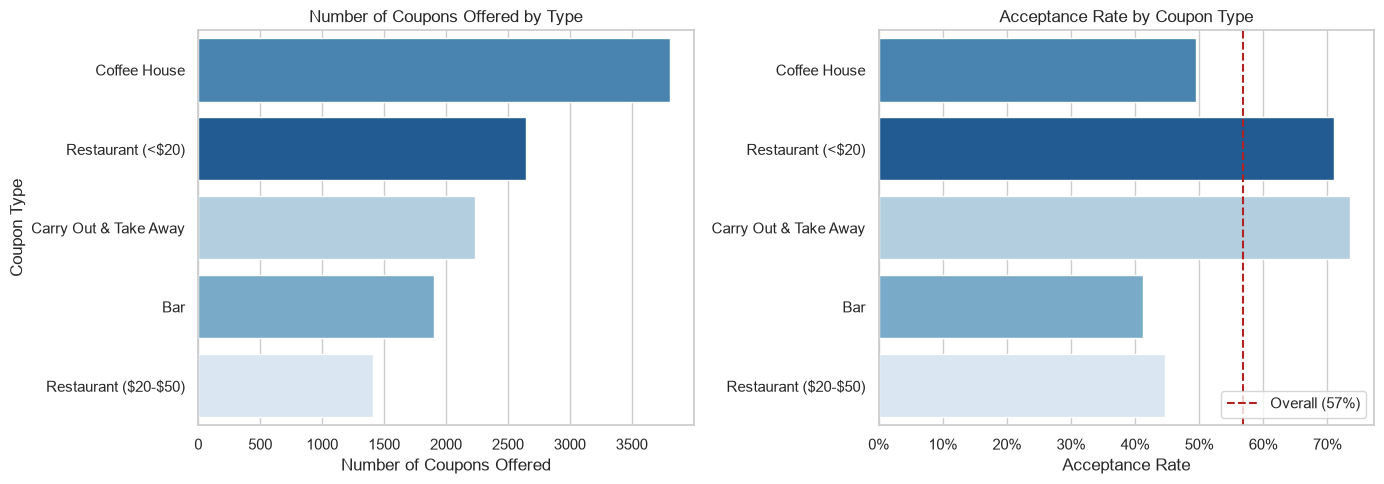

In [8]:
# Order coupon types by how often they were offered
coupon_order = coupons['coupon'].value_counts().index

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=coupons, y='coupon', order=coupon_order, hue='coupon', palette='Blues_r',
              legend=False, ax=axes[0])
axes[0].set_title('Number of Coupons Offered by Type')
axes[0].set_xlabel('Number of Coupons Offered')
axes[0].set_ylabel('Coupon Type')

# Acceptance rate per coupon type, with the overall average as a reference line
sns.barplot(data=coupons, y='coupon', x='Y', order=coupon_order, hue='coupon', palette='Blues_r',
            legend=False, errorbar=None, ax=axes[1])
axes[1].axvline(acceptance_rate, color='firebrick', linestyle='--', label=f'Overall ({acceptance_rate:.0%})')
axes[1].set_title('Acceptance Rate by Coupon Type')
axes[1].set_xlabel('Acceptance Rate')
axes[1].set_ylabel('')
axes[1].xaxis.set_major_formatter(PercentFormatter(1.0))
axes[1].legend(loc='lower right')

# Show coupon names in Title Case on both charts
coupon_labels = {'Coffee House': 'Coffee House', 'Restaurant(<20)': 'Restaurant (<$20)',
                 'Carry out & Take away': 'Carry Out & Take Away', 'Bar': 'Bar',
                 'Restaurant(20-50)': r'Restaurant (\$20-\$50)'}  # escape $ so matplotlib doesn't treat it as math
for ax in axes:
    ax.set_yticks(range(len(coupon_order)), [coupon_labels[c] for c in coupon_order])

plt.tight_layout()
plt.savefig('images/coupon_types.png', bbox_inches='tight')
plt.show()

Coffee House coupons were offered most often, but only about half were accepted. Carry out and cheap restaurant coupons were accepted most often (over 70%), while Bar and more expensive restaurant coupons were accepted least (around 41-44%).

6. Use a histogram to visualize the temperature column.

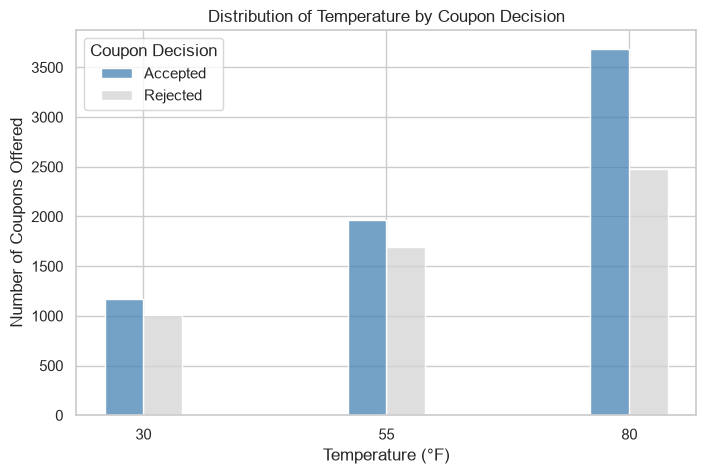

temperature
30    53.8%
55    53.7%
80    59.8%
Name: acceptance_rate, dtype: str

In [9]:
fig, ax = plt.subplots(figsize=(8, 5))
# Temperature only takes three values (30, 55, 80), so use one discrete bin per value
sns.histplot(data=coupons, x='temperature', hue='Y', hue_order=[1, 0], multiple='dodge',
             discrete=True, shrink=8, palette={1: 'steelblue', 0: 'lightgray'}, ax=ax)
ax.set_title('Distribution of Temperature by Coupon Decision')
ax.set_xlabel('Temperature (°F)')
ax.set_ylabel('Number of Coupons Offered')
ax.set_xticks([30, 55, 80])
ax.get_legend().set_title('Coupon Decision')
for text, label in zip(ax.get_legend().texts, ['Accepted', 'Rejected']):
    text.set_text(label)
plt.savefig('images/temperature_hist.png', bbox_inches='tight')
plt.show()

coupons.groupby('temperature')['Y'].mean().map('{:.1%}'.format).rename('acceptance_rate')

Most scenarios took place at 80°F. Acceptance is about 54% at both 30°F and 55°F and rises to about 60% at 80°F.

Investigating the Bar Coupons

Now, we will lead you through an exploration of just the bar related coupons.

1. Create a new `DataFrame` that contains just the bar coupons.

In [10]:
bar_coupons = coupons[coupons['coupon'] == 'Bar'].copy()
bar_coupons.head()

,destination,passenger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,income,Bar,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,Y
24,No Urgent Place,Friend(s),Sunny,80,10AM,Bar,1d,Male,21,Single,...,$62500 - $74999,never,less1,4~8,4~8,less1,0,0,0,1
35,Home,Alone,Sunny,55,6PM,Bar,1d,Male,21,Single,...,$62500 - $74999,never,less1,4~8,4~8,less1,0,0,1,1
39,Work,Alone,Sunny,55,7AM,Bar,1d,Male,21,Single,...,$62500 - $74999,never,less1,4~8,4~8,less1,1,1,0,1
46,No Urgent Place,Friend(s),Sunny,80,10AM,Bar,1d,Male,46,Single,...,$12500 - $24999,never,4~8,1~3,1~3,never,0,0,0,0
57,Home,Alone,Sunny,55,6PM,Bar,1d,Male,46,Single,...,$12500 - $24999,never,4~8,1~3,1~3,never,0,0,1,0


2. What proportion of bar coupons were accepted?

In [11]:
bar_acceptance = bar_coupons['Y'].mean()
print(f'{bar_acceptance:.1%}')

41.2%


Only 41.2% of bar coupons were accepted.

3. Compare the acceptance rate between those who went to a bar 3 or fewer times a month to those who went more.

In [12]:
frequent_bar = bar_coupons['Bar'].isin(['4~8', 'gt8'])
print(f"More than 3 bar visits/month: {bar_coupons[frequent_bar]['Y'].mean():.1%}")
print(f"3 or fewer bar visits/month:  {bar_coupons[~frequent_bar]['Y'].mean():.1%}")

More than 3 bar visits/month: 76.2%
3 or fewer bar visits/month:  37.2%


Drivers who go to a bar more than 3 times a month accept 76% of bar coupons, about twice the rate of those who go 3 or fewer times (37%).

4. Compare the acceptance rate between drivers who go to a bar more than once a month and are over the age of 25 to the all others.  Is there a difference?

In [13]:
bar_regular_over_25 = bar_coupons['Bar'].isin(['1~3', '4~8', 'gt8']) & ~bar_coupons['age'].isin(['below21', '21'])
print(f"Bar >1/month and over 25: {bar_coupons[bar_regular_over_25]['Y'].mean():.1%}")
print(f"All others:               {bar_coupons[~bar_regular_over_25]['Y'].mean():.1%}")

Bar >1/month and over 25: 69.0%
All others:               33.7%


Yes. Drivers who visit bars more than once a month and are over 25 accept 69% of bar coupons compared with 34% of all other drivers, roughly double.

5. Use the same process to compare the acceptance rate between drivers who go to bars more than once a month and had passengers that were not a kid and had occupations other than farming, fishing, or forestry.

In [14]:
bar_regular_no_kids_not_farming = (bar_coupons['Bar'].isin(['1~3', '4~8', 'gt8'])
                                   & (bar_coupons['passenger'] != 'Kid(s)')
                                   & (bar_coupons['occupation'] != 'Farming Fishing & Forestry'))
print(f"Bar >1/month, no kid passengers, not farming/fishing/forestry: "
      f"{bar_coupons[bar_regular_no_kids_not_farming]['Y'].mean():.1%}")
print(f"All others: {bar_coupons[~bar_regular_no_kids_not_farming]['Y'].mean():.1%}")

Bar >1/month, no kid passengers, not farming/fishing/forestry: 70.9%
All others: 29.7%


This group accepts 71% of bar coupons versus 30% for everyone else.

6. Compare the acceptance rates between those drivers who:

- go to bars more than once a month, had passengers that were not a kid, and were not widowed *OR*
- go to bars more than once a month and are under the age of 30 *OR*
- go to cheap restaurants more than 4 times a month and income is less than 50K.

In [15]:
income_under_50k = ['Less than $12500', '$12500 - $24999', '$25000 - $37499', '$37500 - $49999']

regular_no_kids_not_widowed = (bar_coupons['Bar'].isin(['1~3', '4~8', 'gt8'])
                               & (bar_coupons['passenger'] != 'Kid(s)')
                               & (bar_coupons['maritalStatus'] != 'Widowed'))
regular_under_30 = bar_coupons['Bar'].isin(['1~3', '4~8', 'gt8']) & bar_coupons['age'].isin(['below21', '21', '26'])
cheap_dining_low_income = (bar_coupons['RestaurantLessThan20'].isin(['4~8', 'gt8'])
                           & bar_coupons['income'].isin(income_under_50k))

any_condition = regular_no_kids_not_widowed | regular_under_30 | cheap_dining_low_income

# Acceptance rate for each condition on its own, and for the three combined with OR
print(f"Bar >1/month, no kids, not widowed:       {bar_coupons[regular_no_kids_not_widowed]['Y'].mean():.1%}")
print(f"Bar >1/month, under 30:                   {bar_coupons[regular_under_30]['Y'].mean():.1%}")
print(f"Cheap restaurants >4/month, income <$50K: {bar_coupons[cheap_dining_low_income]['Y'].mean():.1%}")
print(f"Any of the three (OR):                    {bar_coupons[any_condition]['Y'].mean():.1%}")
print(f"None of the three:                        {bar_coupons[~any_condition]['Y'].mean():.1%}")

Bar >1/month, no kids, not widowed:       70.9%
Bar >1/month, under 30:                   72.0%
Cheap restaurants >4/month, income <$50K: 45.6%
Any of the three (OR):                    58.7%
None of the three:                        29.9%


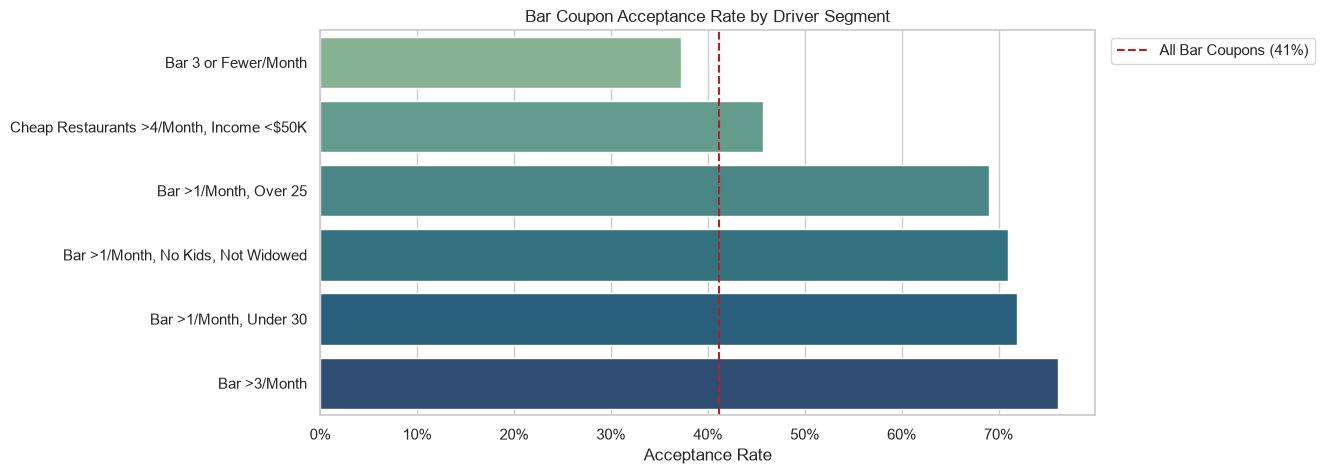

In [16]:
# Visualize every bar-coupon segment from questions 3-6 against the overall bar acceptance rate
segment_rates = pd.Series({
    'Bar >3/Month': bar_coupons.loc[frequent_bar, 'Y'].mean(),
    'Bar >1/Month, Under 30': bar_coupons.loc[regular_under_30, 'Y'].mean(),
    'Bar >1/Month, No Kids, Not Widowed': bar_coupons.loc[regular_no_kids_not_widowed, 'Y'].mean(),
    'Bar >1/Month, Over 25': bar_coupons.loc[bar_regular_over_25, 'Y'].mean(),
    'Cheap Restaurants >4/Month, Income <$50K': bar_coupons.loc[cheap_dining_low_income, 'Y'].mean(),
    'Bar 3 or Fewer/Month': bar_coupons.loc[~frequent_bar, 'Y'].mean(),
}).sort_values()

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(x=segment_rates.values, y=segment_rates.index, hue=segment_rates.index, palette='crest',
            legend=False, ax=ax)
ax.axvline(bar_acceptance, color='firebrick', linestyle='--', label=f'All Bar Coupons ({bar_acceptance:.0%})')
ax.set_title('Bar Coupon Acceptance Rate by Driver Segment')
ax.set_xlabel('Acceptance Rate')
ax.set_ylabel('')
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))  # keep the legend clear of the bars
plt.savefig('images/bar_segments.png', bbox_inches='tight')
plt.show()

The first two conditions (regular bar-goers without kids in the car, and regular bar-goers under 30) both reach about 71-72% acceptance. The third condition (frequent cheap-restaurant diners with income under \$50K) is only slightly above the 41% bar average at 46%. Combining all three with OR gives a group that accepts 59% of bar coupons versus 30% for everyone else.

7.  Based on these observations, what do you hypothesize about drivers who accepted the bar coupons?

Hypothesis: Bar coupon acceptance is driven mostly by *existing bar habits*. Drivers who already go to a bar at least once a month are roughly twice as likely to accept, and the effect is strongest for drivers under 30 and drivers without children in the car. Income and cheap-restaurant habits add little on their own. In short, bar coupons work best for bringing regular bar-goers back, not for converting people who rarely go to bars.

### Independent Investigation: Coffee House Coupons

Using the bar coupon example as motivation, you are to explore one of the other coupon groups and try to determine the characteristics of passengers who accept the coupons.

Problem statement: Coffee House coupons are the most frequently offered coupon (about one in three), yet only about half are accepted. Which drivers are most likely to accept a Coffee House coupon, and how could targeting be improved to raise the acceptance rate?

1. Create a new `DataFrame` that contains just the Coffee House coupons.

In [17]:
coffee_coupons = coupons[coupons['coupon'] == 'Coffee House'].copy()
coffee_coupons.head()

,destination,passenger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,income,Bar,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,Y
23,No Urgent Place,Friend(s),Sunny,80,10AM,Coffee House,2h,Male,21,Single,...,$62500 - $74999,never,less1,4~8,4~8,less1,0,0,0,0
26,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Male,21,Single,...,$62500 - $74999,never,less1,4~8,4~8,less1,0,0,0,0
27,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,2h,Male,21,Single,...,$62500 - $74999,never,less1,4~8,4~8,less1,1,0,0,0
28,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Male,21,Single,...,$62500 - $74999,never,less1,4~8,4~8,less1,1,0,0,0
30,No Urgent Place,Friend(s),Sunny,80,6PM,Coffee House,2h,Male,21,Single,...,$62500 - $74999,never,less1,4~8,4~8,less1,0,0,0,0


2. What proportion of Coffee House coupons were accepted?

In [18]:
coffee_acceptance = coffee_coupons['Y'].mean()
print(f'{coffee_acceptance:.1%}')

49.6%


Only 49.6% of Coffee House coupons were accepted.

3. Compare the acceptance rate between drivers who go to a coffee house at least once a month and those who go less often.

In [19]:
coffee_regular = coffee_coupons['CoffeeHouse'].isin(['1~3', '4~8', 'gt8'])
print(f"1+ coffee house visits/month:  {coffee_coupons[coffee_regular]['Y'].mean():.1%}")
print(f"Less than once/month or never: {coffee_coupons[~coffee_regular]['Y'].mean():.1%}")

1+ coffee house visits/month:  65.9%
Less than once/month or never: 33.9%


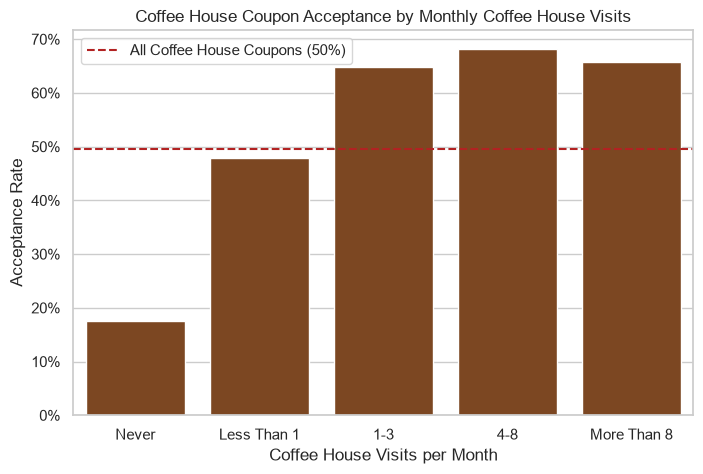

In [20]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=coffee_coupons, x='CoffeeHouse', y='Y', order=['never', 'less1', '1~3', '4~8', 'gt8'],
            color='saddlebrown', errorbar=None, ax=ax)
ax.axhline(coffee_acceptance, color='firebrick', linestyle='--', label=f'All Coffee House Coupons ({coffee_acceptance:.0%})')
ax.set_xticks(range(5), ['Never', 'Less Than 1', '1-3', '4-8', 'More Than 8'])
ax.set_title('Coffee House Coupon Acceptance by Monthly Coffee House Visits')
ax.set_xlabel('Coffee House Visits per Month')
ax.set_ylabel('Acceptance Rate')
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.legend(loc='upper left')
plt.savefig('images/coffee_visits.png', bbox_inches='tight')
plt.show()

Drivers who go to a coffee house at least once a month accept 66% of Coffee House coupons, about twice the rate of those who go less often (34%). Drivers who never go to coffee houses accept only 18%.

4. Compare the acceptance rate between drivers who go to a coffee house at least once a month and are under the age of 30 to all others.

In [21]:
regular_under_30 = coffee_regular & coffee_coupons['age'].isin(['below21', '21', '26'])
print(f"Coffee house 1+/month and under 30: {coffee_coupons[regular_under_30]['Y'].mean():.1%}")
print(f"All others:                         {coffee_coupons[~regular_under_30]['Y'].mean():.1%}")

Coffee house 1+/month and under 30: 68.6%
All others:                         43.3%


Regular coffee house visitors under 30 accept 69% of Coffee House coupons compared with 43% of all other drivers.

5. Compare the acceptance rate between drivers who go to a coffee house at least once a month and have an income under 50K to all others.

In [22]:
regular_low_income = coffee_regular & coffee_coupons['income'].isin(income_under_50k)
print(f"Coffee house 1+/month and income <$50K: {coffee_coupons[regular_low_income]['Y'].mean():.1%}")
print(f"All others:                             {coffee_coupons[~regular_low_income]['Y'].mean():.1%}")

Coffee house 1+/month and income <$50K: 69.5%
All others:                             42.4%


Regular coffee house visitors with an income under \$50K accept 70% of Coffee House coupons compared with 42% of all other drivers.

6. Do demographics on their own make a difference?

In [23]:
print(f"Female: {coffee_coupons[coffee_coupons['gender'] == 'Female']['Y'].mean():.1%}")
print(f"Male:   {coffee_coupons[coffee_coupons['gender'] == 'Male']['Y'].mean():.1%}")
print(f"Has children: {coffee_coupons[coffee_coupons['has_children'] == 1]['Y'].mean():.1%}")
print(f"No children:  {coffee_coupons[coffee_coupons['has_children'] == 0]['Y'].mean():.1%}")

Female: 49.0%
Male:   50.1%
Has children: 48.7%
No children:  50.1%


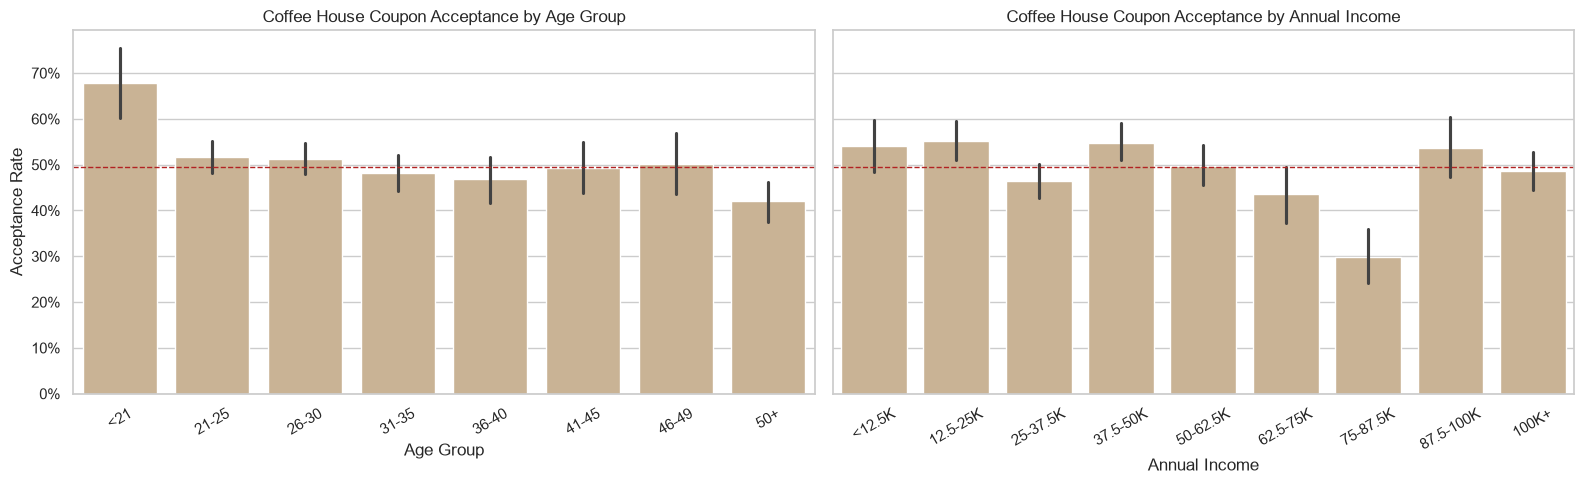

In [24]:
age_order = ['below21', '21', '26', '31', '36', '41', '46', '50plus']
age_labels = ['<21', '21-25', '26-30', '31-35', '36-40', '41-45', '46-49', '50+']
income_order = ['Less than $12500', '$12500 - $24999', '$25000 - $37499', '$37500 - $49999', '$50000 - $62499',
                '$62500 - $74999', '$75000 - $87499', '$87500 - $99999', '$100000 or More']
income_labels = ['<12.5K', '12.5-25K', '25-37.5K', '37.5-50K', '50-62.5K',
                 '62.5-75K', '75-87.5K', '87.5-100K', '100K+']

fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
for ax, feature, order, labels, title in [
        (axes[0], 'age', age_order, age_labels, 'Age Group'),
        (axes[1], 'income', income_order, income_labels, 'Annual Income')]:
    sns.barplot(data=coffee_coupons, x=feature, y='Y', order=order, color='tan', errorbar=('ci', 95), ax=ax)
    ax.axhline(coffee_acceptance, color='firebrick', linestyle='--', linewidth=1)
    ax.set_xticks(range(len(labels)), labels, rotation=30)
    ax.set_title(f'Coffee House Coupon Acceptance by {title}')
    ax.set_xlabel(title)
    ax.set_ylabel('Acceptance Rate')
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
plt.tight_layout()
plt.savefig('images/coffee_demographics.png', bbox_inches='tight')
plt.show()

Gender and children make almost no difference (49% vs 50% in both cases). Most age and income groups sit close to the 50% average with overlapping confidence intervals. Drivers under 21 accept more often (68%) and drivers 50+ less often (42%), and the \$75K-\$87.5K income group is notably low (30%), but these are smaller groups and the pattern is not consistent across neighboring categories. Demographics are a much weaker signal than coffee house habits.

7. Based on these observations, what do you hypothesize about drivers who accepted the Coffee House coupons?

Hypothesis: As with bar coupons, Coffee House coupon acceptance is driven mostly by existing habits. Drivers who already go to a coffee house at least once a month are about twice as likely to accept, and younger and lower-income regulars are the most receptive. Demographics on their own make little difference. Coffee House coupons work best for bringing regular customers back, not for converting people who never visit coffee houses.

### Findings

Overall

- 56.8% of all coupons were accepted. Carry out (73%) and cheap restaurant (71%) coupons perform best; Bar (41%) and expensive restaurant (44%) coupons perform worst.

Bar coupons (41% accepted)

- Existing habit is the strongest predictor: drivers who visit bars more than 3 times a month accept 76% versus 37% for others.
- Regular bar-goers (more than once a month) who are under 30, or who don't have kids in the car, accept about 71-72%.
- Cheap-restaurant habits combined with income under \$50K make little difference (46% vs 40%).

Coffee House coupons (50% accepted)

- Habit dominates: drivers who visit coffee houses at least once a month accept 66%, versus 34% for those who go less often. Drivers who never go accept only 18%.
- Regulars who are under 30 (69%) or have an income under \$50K (70%) are the most receptive.
- Demographics on their own (gender, children, most age and income groups) have little effect.

### Actionable Recommendations

1. Target by habit first. Prioritize sending Coffee House and Bar coupons to drivers who already visit those venues at least once a month.
2. Stop or sharply reduce Coffee House coupons for drivers who never visit coffee houses (18% acceptance).
3. Among regular coffee house visitors, prioritize drivers under 30 and those with an income under \$50K.
4. For bar coupons, focus on regular bar-goers under 30 and never send them when kids are in the car.

### Next Steps

- Build a classification model (e.g. logistic regression or a decision tree) to predict acceptance and rank which factors matter most when considered together.
- Explore situational factors such as time of day, destination and coupon expiration, which this analysis did not cover.
- Repeat this analysis for the Carry out and Restaurant(20-50) coupon groups.
- Keep in mind that this is survey data about hypothetical scenarios; real redemption data would be needed to validate these findings.